# 种植模块：1/3 资源情景的 Gurobi MILP

本 notebook 复用 `planting_gurobi_milp.ipynb` 的变量定义、作物日事件、土地、工具升级和现金流约束；唯一的情景变化是种植模块每天只可使用全局资源的 **1/3**。

- 日时间上限：`900 / 3 = 300` 游戏分钟；
- 日体力上限：`270 / 3 = 90`；
- 初始现金：`500 / 3 = 166.67g`。

收获收入仍归该模块独立现金账户。结果写入 `planting/outputs/one_third_resources/`，不会覆盖完整资源情景的结果。

## 0. 环境、路径与情景设置

需要 `pandas`、`matplotlib` 和具有有效许可证的 `gurobipy`。从项目根目录或 `planting/notebooks/` 启动均可。

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

try:
    import gurobipy as gp
    from gurobipy import GRB
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError('未找到 gurobipy；请安装并配置有效 Gurobi 许可证。') from exc

RESOURCE_SHARE = 1 / 3
SCENARIO_NAME = 'one_third_resources'

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'planting' / 'data').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('找不到项目根目录：应包含 planting/data/。')
PLANTING_DATA = PROJECT_ROOT / 'planting' / 'data'
SHARED_DATA = PROJECT_ROOT / 'shared' / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'planting' / 'outputs' / SCENARIO_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Project root: {PROJECT_ROOT}')
print(f'Output folder: {OUTPUT_DIR}')

Project root: /Users/zoukaiyun/NUS/DBA5103/ProjectImplementation
Output folder: /Users/zoukaiyun/NUS/DBA5103/ProjectImplementation/planting/outputs/one_third_resources


## 1. 读取数据与构造参数

`crop_daily_events.csv` 决定历史种植批次在每一天产生的浇水、收获、土地释放和收入事件。`planting_tool_catalog.csv` 是工具效率与升级成本的权威来源。

In [2]:
calendar = pd.read_csv(PLANTING_DATA / 'crop_planting_calendar.csv')
events = pd.read_csv(PLANTING_DATA / 'crop_daily_events.csv')
crops = pd.read_csv(PLANTING_DATA / 'crops.csv')
tools = pd.read_csv(PLANTING_DATA / 'planting_tool_catalog.csv')
global_parameters = pd.read_csv(SHARED_DATA / 'global_parameters.csv')

def global_value(parameter_id, cast=float):
    return cast(global_parameters.loc[global_parameters.parameter_id.eq(parameter_id), 'value'].iloc[0])

def as_bool(value):
    return str(value).strip().lower() == 'true'

T = list(range(1, 113))
C = sorted(calendar.crop_key.unique())
J, K, UPGRADE_K = ['H', 'W'], [0, 1, 2, 3], [1, 2, 3]
tier_name = {0: 'Basic', 1: 'Copper', 2: 'Steel', 3: 'Gold'}
tool_name = {'H': 'Hoe', 'W': 'Watering Can'}

A = {(r.crop_key, int(r.plant_day)): int(as_bool(r.plant_allowed_A_ct))
     for r in calendar.itertuples(index=False)}
seed_price_by_id = crops.groupby('seed_id').seed_price_g.first().to_dict()
seed_id_by_crop = {r.crop_key: int(r.seed_id) for r in calendar.itertuples(index=False)}
p = {c: float(seed_price_by_id[seed_id_by_crop[c]]) for c in C}
crop_name = calendar.groupby('crop_key').crop_name.first().to_dict()

event_lookup = events.set_index(['crop_key', 'plant_day', 'calendar_day'])
def event_value(c, s, t, column, cast=float):
    key = (c, s, t)
    return cast(event_lookup.loc[key, column]) if key in event_lookup.index else cast(0)

h = {(c, s, t): event_value(c, s, t, 'is_harvest', lambda v: int(as_bool(v)))
     for c in C for s in T for t in T if s <= t}
f = {(c, s, t): event_value(c, s, t, 'releases_land', lambda v: int(as_bool(v)))
     for c in C for s in T for t in T if s <= t}
w_need = {(c, s, t): event_value(c, s, t, 'needs_water', lambda v: int(as_bool(v)))
          for c in C for s in T for t in T if s <= t}
revenue = {(c, s, t): event_value(c, s, t, 'base_revenue_g_per_tile_harvest', float)
           for c in C for s in T for t in T if s <= t}

tool_row = tools.set_index(['tool_type', 'tier'])
tau = {(j, k): float(tool_row.loc[(tool_name[j], tier_name[k]), 'time_game_minutes_per_unit'])
       for j in J for k in K}
energy = {(j, k): float(tool_row.loc[(tool_name[j], tier_name[k]), 'energy_per_unit'])
          for j in J for k in K}
kappa = {k: float(tool_row.loc[('Watering Can', tier_name[k]), 'upgrade_cash_equivalent_cost_g'])
         for k in UPGRADE_K}

TIME_LIMIT_FULL = global_value('daily_time_limit_game_minutes')
ENERGY_LIMIT_FULL = global_value('daily_energy_limit')
INITIAL_CASH_FULL = global_value('initial_gold_g')
TIME_LIMIT = TIME_LIMIT_FULL * RESOURCE_SHARE
ENERGY_LIMIT = ENERGY_LIMIT_FULL * RESOURCE_SHARE
INITIAL_CASH = INITIAL_CASH_FULL * RESOURCE_SHARE
DELTA = {t: int(t in {1, 29, 57, 85}) for t in T}
# Safe Big-M bounds scaled consistently with the allocated daily time.
M_L = M_W = int(TIME_LIMIT // 1.4)
X_UB = int(TIME_LIMIT // (1.4 + 1.4))
print(f'Resource share: {RESOURCE_SHARE:.3f}; time={TIME_LIMIT:g}, energy={ENERGY_LIMIT:g}, initial cash={INITIAL_CASH:.2f}g')

Resource share: 0.333; time=300, energy=90, initial cash=166.67g


## 2. 变量、目标与约束

变量及约束与审核稿一致：`x` 为种植量，`L/S_land` 为耕地与空闲土地，`U/S_tool/D/Z` 描述工具升级、状态、服务期和可用性，`B` 为日末现金。

关键约束包括：种植日历、日事件映射、土地平衡、顺序工具升级、送修两日不可用、每日最多送修一把工具、整地与浇水工具连接、时间/体力上限和日初现金支付。

In [3]:
model = gp.Model('stardew_planting_one_third_resources')
model.ModelSense = GRB.MAXIMIZE

x = model.addVars(C, T, vtype=GRB.INTEGER, lb=0, ub=X_UB, name='x')
L = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='L')
S_land = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='S_land')
H = model.addVars(C, T, vtype=GRB.INTEGER, lb=0, name='H')
W = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='W')
F = model.addVars(T, vtype=GRB.INTEGER, lb=0, name='F')
U = model.addVars(J, UPGRADE_K, T, vtype=GRB.BINARY, name='U')
S_tool = model.addVars(J, K, T, vtype=GRB.BINARY, name='S_tool')
D = model.addVars(J, T, vtype=GRB.BINARY, name='D')
Z = model.addVars(J, K, T, vtype=GRB.BINARY, name='Z')
till = model.addVars(K, T, vtype=GRB.INTEGER, lb=0, name='till')
water = model.addVars(K, T, vtype=GRB.INTEGER, lb=0, name='water')
B = model.addVars(range(113), lb=0, name='B')
crop_revenue = model.addVars(T, lb=0, name='CropRevenue')
seed_cost = model.addVars(T, lb=0, name='SeedCost')
upgrade_cost = model.addVars(T, lb=0, name='UpgradeCost')
time_used = model.addVars(T, lb=0, name='TimeUsed')
energy_used = model.addVars(T, lb=0, name='EnergyUsed')

# Crop calendar, daily crop events, and seasonal empty-land balance.
for c in C:
    for t in T:
        model.addConstr(x[c, t] <= X_UB * A[c, t], name=f'plant_allowed[{c},{t}]')
for t in T:
    model.addConstrs((H[c, t] == gp.quicksum(h[c, s, t] * x[c, s] for s in T if s <= t) for c in C),
                     name=f'harvest_event_day_{t}')
    model.addConstr(F[t] == gp.quicksum(f[c, s, t] * x[c, s] for c in C for s in T if s <= t), name=f'land_release[{t}]')
    model.addConstr(W[t] == gp.quicksum(w_need[c, s, t] * x[c, s] for c in C for s in T if s <= t), name=f'water_need[{t}]')
    model.addConstr(crop_revenue[t] == gp.quicksum(revenue[c, s, t] * x[c, s] for c in C for s in T if s <= t), name=f'crop_revenue[{t}]')
    prev_empty = 0 if t == 1 else S_land[t - 1]
    model.addConstr(S_land[t] == (1 - DELTA[t]) * prev_empty + L[t] + F[t] - gp.quicksum(x[c, t] for c in C), name=f'land_balance[{t}]')

# Tool tiers, sequential upgrades, two-day service, and actual availability.
for j in J:
    model.addConstr(S_tool[j, 0, 1] == 1, name=f'initial_basic[{j}]')
    for k in UPGRADE_K:
        model.addConstr(S_tool[j, k, 1] == 0, name=f'initial_no_upgrade[{j},{k}]')
    for t in T:
        model.addConstr(gp.quicksum(S_tool[j, k, t] for k in K) == 1, name=f'exact_tool_tier[{j},{t}]')
        for k in UPGRADE_K:
            model.addConstr(U[j, k, t] <= S_tool[j, k - 1, t], name=f'sequential_upgrade[{j},{k},{t}]')
        u_today = gp.quicksum(U[j, k, t] for k in UPGRADE_K)
        u_yesterday = 0 if t == 1 else gp.quicksum(U[j, k, t - 1] for k in UPGRADE_K)
        model.addConstr(D[j, t] == u_today + u_yesterday, name=f'service_state[{j},{t}]')
        model.addConstr(u_today + u_yesterday <= 1, name=f'no_resubmit[{j},{t}]')
        if t >= 2:
            for k in K:
                leave_old = 0 if k == 3 or t == 2 else U[j, k + 1, t - 2]
                enter_new = 0 if k == 0 or t == 2 else U[j, k, t - 2]
                model.addConstr(S_tool[j, k, t] == S_tool[j, k, t - 1] - leave_old + enter_new, name=f'tool_state_transition[{j},{k},{t}]')
        for k in K:
            model.addConstr(Z[j, k, t] <= S_tool[j, k, t], name=f'available_only_owned[{j},{k},{t}]')
            model.addConstr(Z[j, k, t] <= 1 - D[j, t], name=f'not_in_service[{j},{k},{t}]')
            model.addConstr(Z[j, k, t] >= S_tool[j, k, t] - D[j, t], name=f'available_when_owned[{j},{k},{t}]')

for t in T:
    model.addConstr(gp.quicksum(U[j, k, t] for j in J for k in UPGRADE_K) <= 1, name=f'one_tool_submission_per_day[{t}]')
    model.addConstr(gp.quicksum(till[k, t] for k in K) == L[t], name=f'till_all_new_land[{t}]')
    model.addConstr(gp.quicksum(water[k, t] for k in K) == W[t], name=f'water_all_required[{t}]')
    for k in K:
        model.addConstr(till[k, t] <= M_L * Z['H', k, t], name=f'till_requires_hoe[{k},{t}]')
        model.addConstr(water[k, t] <= M_W * Z['W', k, t], name=f'water_requires_can[{k},{t}]')
    model.addConstr(time_used[t] == gp.quicksum(tau['H', k] * till[k, t] for k in K) + 1.4 * gp.quicksum(x[c, t] for c in C) + gp.quicksum(tau['W', k] * water[k, t] for k in K) + 1.4 * gp.quicksum(H[c, t] for c in C), name=f'time_accounting[{t}]')
    model.addConstr(energy_used[t] == gp.quicksum(energy['H', k] * till[k, t] for k in K) + gp.quicksum(energy['W', k] * water[k, t] for k in K), name=f'energy_accounting[{t}]')
    model.addConstr(time_used[t] <= TIME_LIMIT, name=f'time_limit[{t}]')
    model.addConstr(energy_used[t] <= ENERGY_LIMIT, name=f'energy_limit[{t}]')

model.addConstr(B[0] == INITIAL_CASH, name='initial_cash')
for t in T:
    model.addConstr(seed_cost[t] == gp.quicksum(p[c] * x[c, t] for c in C), name=f'seed_cost[{t}]')
    model.addConstr(upgrade_cost[t] == gp.quicksum(kappa[k] * U[j, k, t] for j in J for k in UPGRADE_K), name=f'upgrade_cost[{t}]')
    model.addConstr(B[t - 1] >= seed_cost[t] + upgrade_cost[t], name=f'cash_before_spending[{t}]')
    model.addConstr(B[t] == B[t - 1] - seed_cost[t] - upgrade_cost[t] + crop_revenue[t], name=f'cash_balance[{t}]')

model.setObjective(B[112], GRB.MAXIMIZE)
model.update()
print(f'Variables: {model.NumVars:,}; constraints: {model.NumConstrs:,}')

Set parameter Username
Set parameter LicenseID to value 2852968
Academic license - for non-commercial use only - expires 2027-08-12
Variables: 11,201; constraints: 14,001


## 3. 求解、输出与审计

每个结果文件名均带有 `one_third_resources` 标记。日度 CSV 一行对应一天，可直接用于和 mining / fishing 的 1/3 资源基准结果比较。

Set parameter MIPGap to value 0.001
Gurobi Optimizer version 13.0.2 build v13.0.2rc1 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M1 Pro
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Non-default parameters:
MIPGap  0.001

Optimize a model with 14001 rows, 11201 columns and 52210 nonzeros (Max)
Model fingerprint: 0xdbd9e579
Model has 1 linear objective coefficients
Variable types: 673 continuous, 10528 integer (2688 binary)
Coefficient statistics:
  Matrix range     [1e-01, 1e+04]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+02]
  RHS range        [1e+00, 3e+02]

Presolve removed 9514 rows and 7780 columns
Presolve time: 0.12s
Presolved: 4487 rows, 3421 columns, 24947 nonzeros
Variable types: 0 continuous, 3421 integer (1965 binary)

Root relaxation: objective 1.150071e+05, 3392 iterations, 0.11 seconds (0.18 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf

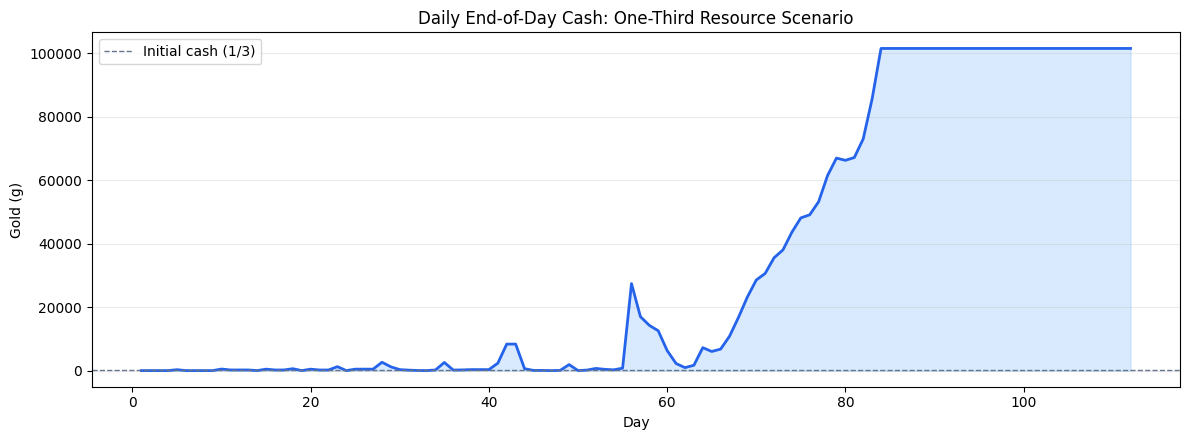

,day,season_day,hoe_status,watering_can_status,new_tilled,plant_decision,watered,harvest_decision,released_land,empty_land_end,seed_cost_g,upgrade_cost_g,revenue_g,time_minutes,energy,cash_end_g,upgrade_submitted
0,1,Spring 1,Basic,Basic,8.0,Parsnip x 8,8.0,-,-0.0,-0.0,160.0,0.0,0.0,33.6,24.0,6.666667,-
1,2,Spring 2,Basic,Basic,0.0,-,8.0,-,-0.0,0.0,0.0,0.0,0.0,11.2,8.0,6.666667,-
2,3,Spring 3,Basic,Basic,0.0,-,8.0,-,-0.0,-0.0,0.0,0.0,0.0,11.2,8.0,6.666667,-
3,4,Spring 4,Basic,Basic,0.0,-,8.0,-,-0.0,0.0,0.0,0.0,0.0,11.2,8.0,6.666667,-
4,5,Spring 5,Basic,Basic,0.0,-,0.0,Parsnip x 8,8.0,8.0,0.0,0.0,280.0,11.2,0.0,286.666667,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,108,Winter 24,Basic,Copper,-0.0,-,-0.0,-,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,101446.666667,-
108,109,Winter 25,Basic,Copper,-0.0,-,-0.0,-,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,101446.666667,-
109,110,Winter 26,Basic,Copper,-0.0,-,-0.0,-,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,101446.666667,-
110,111,Winter 27,Basic,Copper,-0.0,-,-0.0,-,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,101446.666667,-


Audit passed. Outputs written to: /Users/zoukaiyun/NUS/DBA5103/ProjectImplementation/planting/outputs/one_third_resources


In [4]:
model.Params.MIPGap = 0.001
model.optimize()

if model.Status in {GRB.OPTIMAL, GRB.TIME_LIMIT} and model.SolCount > 0:
    print(f'Status: {model.Status}; objective (Day 112 cash): {B[112].X:,.2f}g')

    def season_label(t):
        seasons = ['Spring', 'Summer', 'Fall', 'Winter']
        return f'{seasons[(t - 1) // 28]} {(t - 1) % 28 + 1}'

    def crop_summary(values):
        values = [f'{crop_name[c]} x {value:,.0f}' for c, value in values if value > 0.5]
        return '; '.join(values) if values else '-'

    def tool_status(j, t):
        if D[j, t].X > 0.5:
            return 'in_service'
        return tier_name[next(k for k in K if Z[j, k, t].X > 0.5)]

    rows = []
    for t in T:
        submitted = [f'{tool_name[j]}->{tier_name[k]}' for j in J for k in UPGRADE_K if U[j, k, t].X > 0.5]
        rows.append({
            'day': t, 'season_day': season_label(t),
            'hoe_status': tool_status('H', t), 'watering_can_status': tool_status('W', t),
            'new_tilled': L[t].X,
            'plant_decision': crop_summary([(c, x[c, t].X) for c in C]),
            'watered': W[t].X,
            'harvest_decision': crop_summary([(c, H[c, t].X) for c in C]),
            'released_land': F[t].X, 'empty_land_end': S_land[t].X,
            'seed_cost_g': seed_cost[t].X, 'upgrade_cost_g': upgrade_cost[t].X,
            'revenue_g': crop_revenue[t].X, 'time_minutes': time_used[t].X,
            'energy': energy_used[t].X, 'cash_end_g': B[t].X,
            'upgrade_submitted': ', '.join(submitted) or '-'
        })
    daily_solution = pd.DataFrame(rows)
    daily_solution.to_csv(OUTPUT_DIR / 'daily_decisions_one_third_resources.csv', index=False, encoding='utf-8-sig')

    batches = pd.DataFrame([{'crop_key': c, 'crop_name': crop_name[c], 'plant_day': t, 'season_day': season_label(t), 'tiles': x[c, t].X}
                            for c in C for t in T if x[c, t].X > 0.5])
    if not batches.empty:
        batches.sort_values(['plant_day', 'crop_key']).to_csv(OUTPUT_DIR / 'planting_batches_one_third_resources.csv', index=False, encoding='utf-8-sig')

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(daily_solution['day'], daily_solution['cash_end_g'], color='#2563EB', linewidth=2)
    ax.fill_between(daily_solution['day'], daily_solution['cash_end_g'], color='#93C5FD', alpha=0.35)
    ax.axhline(INITIAL_CASH, color='#64748B', linestyle='--', linewidth=1, label='Initial cash (1/3)')
    ax.set(title='Daily End-of-Day Cash: One-Third Resource Scenario', xlabel='Day', ylabel='Gold (g)')
    ax.grid(axis='y', alpha=0.25); ax.legend(); fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'daily_cash_balance_one_third_resources.png', dpi=160, bbox_inches='tight')
    plt.show()

    display(daily_solution)
    assert daily_solution['time_minutes'].max() <= TIME_LIMIT + 1e-6
    assert daily_solution['energy'].max() <= ENERGY_LIMIT + 1e-6
    assert daily_solution['cash_end_g'].min() >= -1e-6
    assert all(sum(U[j, k, t].X for j in J for k in UPGRADE_K) <= 1 + 1e-6 for t in T)
    print(f'Audit passed. Outputs written to: {OUTPUT_DIR}')
else:
    print(f'No usable solution. Gurobi status: {model.Status}')
    if model.Status == GRB.INFEASIBLE:
        model.computeIIS()
        model.write(str(OUTPUT_DIR / 'planting_one_third_resources_infeasible.ilp'))